# Data Engineering: Spark Locally

> **Who is this for:** you have done [02 · Big data processing on one machine](02_big_data_processing_on_one_machine.ipynb) (MapReduce, Parquet, skew) and want to understand **Apache Spark**, the most widely used engine for large-scale data processing and the engine under Databricks, AWS EMR and Google Dataproc. It is also for students in a "Big Data Analytics" course and for data/ML-engineering interviews, where "what is a shuffle?" and "broadcast vs sort-merge join" are standard questions.
>
> **What you will learn:**
> - Spark's architecture: **driver, executors, partitions, DAG**, jobs, stages and tasks; **lazy evaluation**; transformations vs actions
> - A local `SparkSession` (`local[*]`), the **DataFrame API** and **Spark SQL**
> - **Narrow vs wide** transformations, **shuffles**, reading a query plan, **caching** and persistence
> - Joins: **broadcast hash join vs sort-merge join**, and fixing skew with **salting**
> - **Window functions**, and why **built-in functions beat Python UDFs** (and pandas UDFs sit in between)
> - Writing **partitioned Parquet** and the **small-files problem**
> - An **MLlib pipeline**: feature assembler, logistic regression, cross-validation
> - **Structured Streaming** with the rate source and **watermarks**; how all this maps to Databricks and EMR
>
> **Prerequisites:** [02 · Big data on one machine](02_big_data_processing_on_one_machine.ipynb); [DuckDB](../../02_Data_Analysis/10_duckdb.ipynb) (SQL, window functions); [SQL fundamentals](../01_sql/01_sql_fundamentals.ipynb); [query processing](../00_dbms_fundamentals/08_query_processing_and_optimization.ipynb) (join algorithms) is helpful.
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet. **PySpark is optional.** Spark needs the `pyspark` package and a Java runtime (Java 17 or 21 for Spark 4.x). If either is missing, every Spark cell prints a one-line "skipped" message, and the same idea runs in a **pure-Python mini-Spark** built in this notebook, or in DuckDB, pandas and scikit-learn. The notebook runs in about one minute without Spark.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Zaharia et al., "Resilient Distributed Datasets" (NSDI 2012) and Chambers & Zaharia, *Spark: The Definitive Guide*.

## Explained simply

**Apache Spark** is a program that lets many computers work together on one huge table as if it were a single pandas DataFrame. You write normal-looking code ("group these sales by country and add them up"); Spark cuts the table into pieces called **partitions**, sends the pieces to many workers, and puts the answers back together. A useful trick is that Spark is **lazy**: it first writes down your whole recipe, then plans the fastest way to cook it, and only starts when you ask for a result. Think of a restaurant: the head chef (the **driver**) reads the order and splits it into jobs, and the line cooks (the **executors**) each prepare part of it at the same time. The expensive moment is when ingredients must be passed between cooks (a **shuffle**), so good Spark code passes as little as possible. Another picture: a teacher marking 1,000 exam papers alone versus handing 100 papers to each of 10 teaching assistants, then collecting only their totals.

**Tiny example.** 6 sales: PK 10, US 5, PK 7, IN 3, US 2, PK 1, split into 2 partitions of 3. Worker A adds its part: PK 17, US 5. Worker B adds its part: IN 3, US 2, PK 1. Only these small subtotals are passed around (the shuffle), and the final answer is PK 18, US 7, IN 3.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Driver and executors | one boss plans the work, many workers do pieces of it | Databricks clusters, AWS EMR jobs |
| Shuffle | moving data between workers so equal keys meet | every group-by and join on big tables |
| Lazy evaluation | write down the whole recipe first, cook only when asked | Spark, Polars lazy, DuckDB query plans, TensorFlow graphs |

### How this notebook is different from `01` and `02`
[`01_data_engineering`](01_data_engineering.ipynb) shows Spark code as text without running it. [`02`](02_big_data_processing_on_one_machine.ipynb) builds MapReduce, Parquet tricks and skew handling on one machine. Here we focus on **Spark's own model**: lazy DAGs, stages, the DataFrame/SQL API, join strategies, MLlib and Structured Streaming. Every Spark cell is real PySpark code; when PySpark is unavailable, a fallback cell shows the same mechanism.

## Table of contents
0. Setup: is Spark available?
1. Spark architecture in one picture
2. A mini-Spark from scratch: lazy RDDs, narrow and wide dependencies
3. Shuffles: `reduceByKey` vs `groupByKey`
4. The DataFrame API and Spark SQL
5. Caching and persistence
6. Joins: broadcast hash join, sort-merge join, and skew
7. Window functions and UDFs
8. Partitioned Parquet and the small-files problem
9. MLlib: a pipeline with cross-validation
10. Structured Streaming: rate source and watermarks
11. Spark in the cloud: Databricks, EMR and friends
12. How this connects to modern AI
13. Recap, practice problems, further reading

---
## 0. Setup: is Spark available?

We check for the `pyspark` package and a `java` program. If both exist, we start a local Spark session with 2 worker threads (`local[2]`), 8 shuffle partitions (the default of 200 is far too many for small data) and the web UI switched off.

In [1]:
import os, sys, time, shutil, tempfile, zlib, random, importlib.util
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
import pyarrow as pa
import pyarrow.dataset as ds

WORK = Path(tempfile.mkdtemp(prefix="spark_local_"))     # everything we write goes here; deleted at the end
RNG = np.random.default_rng(7)
random.seed(7)

HAS_PYSPARK = importlib.util.find_spec("pyspark") is not None
HAS_JAVA = shutil.which("java") is not None
spark = None                                             # stays None when Spark is unavailable
if HAS_PYSPARK and HAS_JAVA:
    # Spark starts its Python workers with "python3" from PATH unless told otherwise: use this kernel's Python.
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    os.environ.setdefault("SPARK_LOCAL_IP", "127.0.0.1")       # local mode only needs the loopback address
    try:
        from pyspark.sql import SparkSession, functions as F, Window
        spark = (SparkSession.builder
                 .master("local[2]")                     # driver + 2 worker threads on this machine
                 .appName("spark-locally")
                 .config("spark.sql.shuffle.partitions", "8")
                 .config("spark.ui.enabled", "false")
                 .config("spark.ui.showConsoleProgress", "false")   # no [Stage ...] progress bars in the output
                 .config("spark.driver.memory", "1g")
                 .getOrCreate())
        spark.sparkContext.setLogLevel("ERROR")
        print("Spark", spark.version, "started in local mode")
    except Exception as exc:                             # e.g. an unsupported Java version
        print("Spark could not start:", type(exc).__name__, str(exc)[:200])
        spark = None
SKIP = "⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea."
print(f"pyspark installed: {HAS_PYSPARK} | java found: {HAS_JAVA} | Spark running: {spark is not None}")
print("pandas", pd.__version__, "| duckdb", duckdb.__version__, "| pyarrow", pa.__version__)

pyspark installed: False | java found: True | Spark running: False
pandas 2.3.3 | duckdb 1.5.4 | pyarrow 24.0.0


> 💡 **To run the real Spark cells later:** `pip install pyspark` (the package bundles Spark itself) and install a JDK (Java 17 or 21 for Spark 4.x; Spark 3.5 also accepts Java 8 and 11). Then restart the kernel and run the notebook again. Nothing else changes.

---
## 1. Spark architecture in one picture

> 💬 **In plain English:** one boss process plans the work and many worker processes each handle a slice of the data.

```
                         ┌──────────────────────────┐
  your program  ───────> │ DRIVER (SparkSession)    │  builds the DAG, plans stages,
  (Python)               │  - DAG scheduler         │  schedules tasks, collects results
                         │  - task scheduler        │
                         └────────────┬─────────────┘
                                      │ asks for resources
                         ┌────────────▼─────────────┐
                         │ CLUSTER MANAGER          │  local, standalone, YARN, Kubernetes
                         └────────────┬─────────────┘
              ┌───────────────────────┼───────────────────────┐
     ┌────────▼────────┐     ┌────────▼────────┐     ┌────────▼────────┐
     │ EXECUTOR 1      │     │ EXECUTOR 2      │     │ EXECUTOR 3      │  JVM processes on worker
     │ task task task  │     │ task task       │     │ task task task  │  machines; one task per
     │ cache, shuffle  │<───>│ cache, shuffle  │<───>│ cache, shuffle  │  partition per stage
     └─────────────────┘     └─────────────────┘     └─────────────────┘
                     shuffle = executors exchanging data over the network
```

| term | precise meaning |
|---|---|
| **driver** | the process running your `main` program and the `SparkSession`; it builds the plan and schedules work |
| **executor** | a worker process that runs tasks and stores cached data and shuffle files |
| **partition** | one chunk of a distributed dataset; the unit of parallelism |
| **transformation** | a lazy operation that defines a new dataset (`map`, `filter`, `select`, `groupBy`, `join`) |
| **action** | an operation that returns a result or writes output and therefore **triggers execution** (`count`, `collect`, `show`, `write`) |
| **lineage / DAG** | the directed acyclic graph of transformations that produced a dataset; used for planning and for **recomputing lost partitions** (fault tolerance without replication) |
| **job** | all the work triggered by one action |
| **stage** | a part of a job that runs without a shuffle; **stage boundaries are at wide dependencies** |
| **task** | one stage applied to one partition, run by one executor core |
| **narrow dependency** | each output partition depends on at most one partition of each parent (e.g. `map`, `filter`): no data movement |
| **wide dependency** | an output partition depends on many parent partitions (e.g. `groupByKey`, most joins): requires a **shuffle** |

`local[*]` means "driver and executor in one process on this machine, with one worker thread per core". It runs the same code you would run on a 100-machine cluster, which is why it is the standard way to develop and test Spark jobs.

---
## 2. A mini-Spark from scratch: lazy RDDs, narrow and wide dependencies

> 💬 **In plain English:** we build a tiny Spark so we can watch it be lazy and see where data has to move.

An **RDD** (Resilient Distributed Dataset) is Spark's original abstraction: an immutable, partitioned collection plus the **recipe** (lineage) to compute each partition from its parents. DataFrames are built on the same machinery. To *see* laziness, stages and shuffles, we implement a small RDD engine (about 100 lines). It runs partitions one after another in this process, but it follows Spark's rules:

- transformations only create a new `TinyRDD` object that remembers its parent and a function (nothing runs);
- actions (`collect`, `count`) ask for every partition, which recursively computes parents;
- wide operations (`reduceByKey`, `groupByKey`, `join`) **shuffle**: they compute all parent partitions, hash-partition the records by key and keep the "shuffle files" so a later action can reuse them (Spark calls those *skipped stages*);
- `cache()` keeps computed partitions in memory.

In [2]:
def part_of(key, n):
    # Stable hash partitioner (Python's hash() of str is randomised per process).
    return zlib.crc32(repr(key).encode()) % n

class TinyContext:
    def __init__(self):
        self.metrics = Counter()                       # what work actually happened
    def parallelize(self, data, n_parts=4):
        data = list(data)
        size = -(-len(data) // n_parts)                # ceil: contiguous slices like Spark
        parts = [data[i * size:(i + 1) * size] for i in range(n_parts)]
        return TinyRDD(self, n_parts, lambda i: parts[i], [], "parallelize")

class TinyRDD:
    def __init__(self, ctx, n_parts, compute, parents, name, wide=False):
        self.ctx, self.n_parts, self._compute = ctx, n_parts, compute
        self.parents, self.name, self.wide = parents, name, wide
        self._cache = None                             # dict partition -> data when cached

    # ---------- execution ----------
    def partition(self, i):
        if self._cache is not None and i in self._cache:
            self.ctx.metrics["cache_hits"] += 1
            return self._cache[i]
        self.ctx.metrics["tasks"] += 1
        data = self._compute(i)
        if self._cache is not None:
            self._cache[i] = data
        return data

    def cache(self):
        self._cache = {}
        return self

    # ---------- narrow transformations: partition i depends only on parent partition i ----------
    def _narrow(self, fn, name):
        return TinyRDD(self.ctx, self.n_parts, lambda i: fn(self.partition(i)), [self], name)
    def map(self, f):
        return self._narrow(lambda part: [f(x) for x in part], "map")
    def filter(self, f):
        return self._narrow(lambda part: [x for x in part if f(x)], "filter")
    def flatMap(self, f):
        return self._narrow(lambda part: [y for x in part for y in f(x)], "flatMap")
    def mapValues(self, f):
        return self._narrow(lambda part: [(k, f(v)) for k, v in part], "mapValues")
    def mapPartitions(self, f):
        return self._narrow(lambda part: list(f(part)), "mapPartitions")

    # ---------- wide transformations: need a shuffle ----------
    def _shuffle(self, n_out, map_side=None):
        # Returns a function out_partition -> list of (k, v); shuffle output is computed once and kept.
        files = {}
        def fetch(j):
            if not files:
                buckets = [[] for _ in range(n_out)]
                for i in range(self.n_parts):              # "map side": every parent partition
                    part = self.partition(i)
                    if map_side is not None:
                        part = map_side(part)              # optional map-side combine
                    for k, v in part:
                        buckets[part_of(k, n_out)].append((k, v))
                    self.ctx.metrics["shuffled_records"] += len(part)
                files["data"] = buckets
            return files["data"][j]
        return fetch

    def reduceByKey(self, f, n_out=None):
        n_out = n_out or self.n_parts
        def combine(part):                                 # fold values per key inside one partition
            acc = {}
            for k, v in part:
                acc[k] = f(acc[k], v) if k in acc else v
            return list(acc.items())
        fetch = self._shuffle(n_out, map_side=combine)
        return TinyRDD(self.ctx, n_out, lambda j: combine(fetch(j)), [self], "reduceByKey", wide=True)

    def groupByKey(self, n_out=None):
        n_out = n_out or self.n_parts
        fetch = self._shuffle(n_out)                       # no map-side combine possible
        def group(j):
            g = defaultdict(list)
            for k, v in fetch(j):
                g[k].append(v)
            return list(g.items())
        return TinyRDD(self.ctx, n_out, group, [self], "groupByKey", wide=True)

    def join(self, other, n_out=None):
        # Shuffle (sort-merge) join: co-partition both sides by key, then sort and merge each partition.
        n_out = n_out or max(self.n_parts, other.n_parts)
        left, right = self._shuffle(n_out), other._shuffle(n_out)
        def merge(j):
            L, R = sorted(left(j), key=lambda kv: kv[0]), sorted(right(j), key=lambda kv: kv[0])
            out, a, b = [], 0, 0
            while a < len(L) and b < len(R):
                if L[a][0] < R[b][0]:
                    a += 1
                elif L[a][0] > R[b][0]:
                    b += 1
                else:                                      # equal keys: emit the cross product of both runs
                    key, a2, b2 = L[a][0], a, b
                    while a2 < len(L) and L[a2][0] == key: a2 += 1
                    while b2 < len(R) and R[b2][0] == key: b2 += 1
                    out += [(key, (x[1], y[1])) for x in L[a:a2] for y in R[b:b2]]
                    a, b = a2, b2
            return out
        return TinyRDD(self.ctx, n_out, merge, [self, other], "join", wide=True)

    # ---------- actions: these trigger execution ----------
    def collect(self):
        self.ctx.metrics["jobs"] += 1
        return [x for i in range(self.n_parts) for x in self.partition(i)]
    def count(self):
        self.ctx.metrics["jobs"] += 1
        return sum(len(self.partition(i)) for i in range(self.n_parts))

    # ---------- the lineage, printed like Spark's toDebugString ----------
    def _lines(self):
        out = [f"({self.n_parts}) {self.name}"]
        for p in self.parents:
            sub = p._lines()
            if self.wide:                                  # shuffle dependency: a new stage, indented with +-
                out.append(" +-" + sub[0] + "      <- stage boundary (shuffle)")
                out += ["    " + line for line in sub[1:]]
            else:                                          # narrow dependency: same stage, drawn with |
                out.append(" |  " + sub[0].split(" ", 1)[1])
                out += sub[1:]
        return out
    def toDebugString(self):
        return "\n".join(self._lines())

print("TinyContext / TinyRDD defined")

TinyContext / TinyRDD defined


### 2.1 Laziness in action: word count

We build the classic word count. Watch the metrics: **nothing runs** until the action.

In [3]:
sc = TinyContext()
VOCAB = [f"w{i}" for i in range(300)]
p = 1 / np.arange(1, 301); p /= p.sum()
text = [" ".join(RNG.choice(VOCAB, 12, p=p)) for _ in range(5000)]       # 5,000 lines

lines_rdd = sc.parallelize(text, 4)
pairs = lines_rdd.flatMap(str.split).map(lambda w: (w, 1))               # transformations: lazy
counts = pairs.reduceByKey(lambda a, b: a + b)                           # still lazy
print("after defining the pipeline, metrics =", dict(sc.metrics))        # empty: nothing ran

result = dict(counts.collect())                                          # ACTION: runs everything
truth = Counter(w for line in text for w in line.split())
assert result == truth
print("after collect():", dict(sc.metrics))
print("top 3:", Counter(result).most_common(3))
print()
print(counts.toDebugString())

after defining the pipeline, metrics = {}
after collect(): {'jobs': 1, 'tasks': 16, 'shuffled_records': 1200}
top 3: [('w0', 9468), ('w1', 4766), ('w2', 3287)]

(4) reduceByKey
 +-(4) map      <- stage boundary (shuffle)
     |  flatMap
     |  parallelize


**What just happened?** Defining `flatMap → map → reduceByKey` did no work at all (the metrics stayed empty). `collect()` started one **job**. The lineage shows two **stages**: the bottom one (`parallelize → flatMap → map`, all narrow, pipelined inside each task without materialising intermediate lists in Spark) and the top one after the shuffle. The task counter includes one task per partition per RDD in our simple engine; real Spark fuses a whole stage into one task per partition. Spark's own `toDebugString` looks very similar:

```
(4) PythonRDD[...] at RDD at PythonRDD.scala
 |  MapPartitionsRDD[...] at mapPartitions
 |  ShuffledRDD[...] at partitionBy
 +-(4) PairwiseRDD[...] at reduceByKey
    |  PythonRDD[...] at reduceByKey
    |  ParallelCollectionRDD[...] at readRDDFromFile
```

The real Spark version of the same cell:

In [4]:
if spark is not None:
    sc_real = spark.sparkContext
    rdd = sc_real.parallelize(text, 4)
    counts_real = rdd.flatMap(str.split).map(lambda w: (w, 1)).reduceByKey(lambda a, b: a + b)
    assert dict(counts_real.collect()) == truth
    print(counts_real.toDebugString().decode())
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


---
## 3. Shuffles: `reduceByKey` vs `groupByKey`

> 💬 **In plain English:** moving data between workers is the expensive part; pre-adding on each worker moves much less.

A **shuffle** redistributes records across partitions so that all records with the same key land in the same partition. In a cluster it means: every map task writes its output to local disk, split by destination partition; every reduce task fetches its piece **over the network** from every map task. With $M$ map tasks and $R$ reduce tasks that is $M \times R$ transfers, plus serialisation and disk I/O. Shuffles are usually the most expensive part of a Spark job.

`reduceByKey(f)` applies `f` **on the map side first** (a combiner, as in notebook 02), so each map task sends at most one record per key. `groupByKey()` must send **every** record, then build potentially huge lists on the reduce side.

In [5]:
sc = TinyContext()
pairs = sc.parallelize(text, 4).flatMap(str.split).map(lambda w: (w, 1)).cache()
n_pairs = pairs.count()

before = sc.metrics["shuffled_records"]
via_reduce = dict(pairs.reduceByKey(lambda a, b: a + b).collect())
shuf_reduce = sc.metrics["shuffled_records"] - before

before = sc.metrics["shuffled_records"]
via_group = {k: sum(v) for k, v in pairs.groupByKey().collect()}
shuf_group = sc.metrics["shuffled_records"] - before

assert via_reduce == via_group == truth
print(pd.DataFrame({"operation": ["reduceByKey", "groupByKey + sum"],
                    "records shuffled": [shuf_reduce, shuf_group],
                    "share of input pairs": [f"{shuf_reduce / n_pairs:.1%}", f"{shuf_group / n_pairs:.1%}"]}).to_string(index=False))

       operation  records shuffled share of input pairs
     reduceByKey              1200                 2.0%
groupByKey + sum             60000               100.0%


**What just happened?** Both give the same counts, but `groupByKey` shuffled all 60,000 pairs while `reduceByKey` shuffled at most one record per distinct word per partition, a small fraction. The Spark DataFrame API does this automatically: `df.groupBy("k").agg(F.sum("v"))` plans a **partial aggregation** before the exchange and a **final aggregation** after it.

| narrow (no shuffle) | wide (shuffle) |
|---|---|
| `map`, `filter`, `flatMap`, `mapValues`, `select`, `withColumn`, `where`, `union`, `coalesce(n)` (merging partitions) | `groupByKey`, `reduceByKey`, `groupBy().agg()`, `distinct`, `repartition(n)`, `orderBy`/`sortBy`, most `join`s, window functions with `partitionBy` |

> ⚠️ **Common mistake:** calling `groupByKey()` (or `collect_list`) only to sum, count or average the groups. It shuffles everything and can run an executor out of memory on one hot key. Use `reduceByKey` / `aggregateByKey`, or DataFrame aggregations.

> 🎓 **Exam / interview tip:** "What causes a new stage?" A **wide dependency** (shuffle). "What triggers a job?" An **action**. "How many tasks in a stage?" One per partition of that stage.

---
## 4. The DataFrame API and Spark SQL

> 💬 **In plain English:** Spark tables look and feel like pandas or SQL, but run on many machines.

Most Spark code today uses **DataFrames** (named, typed columns) or **Spark SQL**, not RDDs. Both go through the **Catalyst optimiser**, which rewrites your query (predicate pushdown, column pruning, join reordering, choosing join strategies) and the **Tungsten** execution engine (compact binary rows, generated code). Since Spark 3.2, **Adaptive Query Execution (AQE)** also re-plans at run time using real statistics from completed stages (coalescing small shuffle partitions, switching to broadcast joins, splitting skewed partitions).

We generate an orders table and run the same query in Spark (if available), in Spark SQL, and in the fallbacks DuckDB SQL and pandas.

In [6]:
N = 200_000
days = pd.date_range("2026-09-01", periods=30, freq="D").strftime("%Y-%m-%d").to_numpy()
orders = pd.DataFrame({
    "order_id": np.arange(N),
    "ts": pd.Timestamp("2026-09-01") + pd.to_timedelta(np.sort(RNG.integers(0, 30 * 86400, N)), unit="s"),
    "customer_id": RNG.zipf(1.4, N) % 5000,                         # skewed: a few very busy customers
    "country": RNG.choice(["PK", "US", "IN", "DE", "BR"], N, p=[.3, .25, .2, .15, .1]),
    "category": RNG.choice(["books", "games", "food", "tech"], N),
    "amount": RNG.gamma(2.0, 20.0, N).round(2),
})
orders["day"] = orders["ts"].dt.strftime("%Y-%m-%d")
customers = pd.DataFrame({"customer_id": np.arange(5000),
                          "segment": RNG.choice(["new", "regular", "vip"], 5000, p=[.5, .4, .1])})
print(orders.head(3).to_string(index=False))
print(f"{len(orders):,} orders, {len(customers):,} customers")

# Fallback 1: pandas
pd_res = (orders[orders.amount > 10].groupby(["country", "category"], as_index=False)
          .agg(revenue=("amount", "sum"), n=("order_id", "count"))
          .sort_values(["country", "category"], ignore_index=True))
# Fallback 2: DuckDB SQL (DuckDB can query the pandas DataFrame by its variable name)
con = duckdb.connect()
con.execute("SET threads = 2")
con.execute("SET enable_progress_bar = false")
sql = '''
    SELECT country, category, SUM(amount) AS revenue, COUNT(*) AS n
    FROM orders WHERE amount > 10
    GROUP BY country, category ORDER BY country, category
'''
duck_res = con.execute(sql).df()
pd.testing.assert_frame_equal(pd_res, duck_res, check_dtype=False)
print("pandas and DuckDB agree;", len(duck_res), "groups; first rows:")
print(duck_res.head(4).round(2).to_string(index=False))

 order_id                  ts  customer_id country category  amount        day
        0 2026-09-01 00:00:16          146      US    games   31.63 2026-09-01
        1 2026-09-01 00:00:30           10      US    books   42.07 2026-09-01
        2 2026-09-01 00:00:45           94      US    books   20.87 2026-09-01
200,000 orders, 5,000 customers
pandas and DuckDB agree; 20 groups; first rows:
country category   revenue    n
     BR    books 194549.58 4466
     BR     food 194398.80 4536
     BR    games 195820.45 4485
     BR     tech 197884.91 4507


In [7]:
if spark is not None:
    sdf = spark.createDataFrame(orders.drop(columns=["ts"]))          # driver -> executors
    res = (sdf.where(F.col("amount") > 10)
              .groupBy("country", "category")
              .agg(F.sum("amount").alias("revenue"), F.count("*").alias("n"))
              .orderBy("country", "category"))
    res.explain()                                                     # physical plan
    sdf.createOrReplaceTempView("orders")
    res_sql = spark.sql(sql)                                          # the very same SQL text
    spark_pd = res_sql.toPandas()
    assert np.allclose(spark_pd["revenue"], duck_res["revenue"]) and (spark_pd["n"] == duck_res["n"]).all()
    print("Spark DataFrame API and Spark SQL agree with DuckDB/pandas")
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


**What just happened?** pandas and DuckDB return identical results (and so does Spark when installed). The Spark DataFrame code reads almost like pandas, and `spark.sql` accepts the same SQL as DuckDB. When Spark runs, `explain()` prints a physical plan such as:

| plan operator | meaning |
|---|---|
| `FileScan parquet ... PushedFilters: [...], ReadSchema: ...` | scan with predicate pushdown and column pruning |
| `Filter`, `Project` | row filter, column selection (narrow) |
| `HashAggregate(keys=..., functions=[partial_sum(...)])` | **partial** aggregation before the shuffle (the combiner) |
| `Exchange hashpartitioning(country, category, 8)` | **the shuffle** into 8 partitions |
| `HashAggregate(keys=..., functions=[sum(...)])` | final aggregation after the shuffle |
| `BroadcastHashJoin` / `SortMergeJoin` / `BroadcastExchange` | join strategies (Section 6) |
| `AdaptiveSparkPlan isFinalPlan=false` | AQE may still change the plan at run time |

**Reading rule:** count the `Exchange` operators; each one is a shuffle and a stage boundary.

| task | pandas | Spark DataFrame | SQL (Spark or DuckDB) |
|---|---|---|---|
| filter rows | `df[df.a > 10]` | `df.where(F.col("a") > 10)` | `WHERE a > 10` |
| new column | `df.assign(b=df.a * 2)` | `df.withColumn("b", F.col("a") * 2)` | `SELECT a * 2 AS b` |
| group + aggregate | `df.groupby("k").agg(s=("a", "sum"))` | `df.groupBy("k").agg(F.sum("a").alias("s"))` | `GROUP BY k` |
| join | `df.merge(o, on="k")` | `df.join(o, "k")` | `JOIN o USING (k)` |
| get results | already in memory | `.show()`, `.collect()`, `.toPandas()` (actions!) | `SELECT ...` |

---
## 5. Caching and persistence

> 💬 **In plain English:** if you will use a result several times, keep it in memory instead of recomputing it.

Because Spark is lazy, **every action recomputes the whole lineage** from the source, unless an intermediate result is cached. `cache()` (or `persist(level)`) marks a dataset to be kept after it is first computed. It is itself lazy: the data is stored during the next action.

In [8]:
calls = Counter()
def expensive_parse(line):
    calls["parse"] += 1                        # count how often the "expensive" function really runs
    return line.split()

for use_cache in [False, True]:
    sc = TinyContext(); calls.clear()
    parsed = sc.parallelize(text, 4).map(expensive_parse)
    if use_cache:
        parsed = parsed.cache()
    n_lines = parsed.count()                                        # action 1
    n_words = sum(parsed.map(len).collect())                        # action 2
    n_long = parsed.filter(lambda ws: len(set(ws)) == 12).count()   # action 3
    print(f"cache={use_cache!s:5}: parse() ran {calls['parse']:>6,} times for 3 actions "
          f"(lines={n_lines}, words={n_words}, all-distinct lines={n_long}), cache hits={sc.metrics['cache_hits']}")

cache=False: parse() ran 15,000 times for 3 actions (lines=5000, words=60000, all-distinct lines=621), cache hits=0
cache=True : parse() ran  5,000 times for 3 actions (lines=5000, words=60000, all-distinct lines=621), cache hits=8


**What just happened?** Without caching, three actions parsed all 5,000 lines three times (15,000 calls). With `cache()`, the first action computed and stored the partitions, and the next two actions read them from memory (5,000 calls, 8 cache hits = 2 actions × 4 partitions).

| storage level | where | notes |
|---|---|---|
| `MEMORY_ONLY` | executor RAM, deserialised | `RDD.cache()` default; partitions that do not fit are recomputed |
| `MEMORY_AND_DISK` | RAM, spill to local disk | `DataFrame.cache()` default (deserialised variant); good general choice |
| `DISK_ONLY` | local disk | when recomputation is very expensive and RAM is scarce |
| `*_2` variants | two replicas | faster recovery after losing an executor |

Cache when a dataset is **reused by several actions** (iterative ML, interactive exploration) and is **expensive to recompute**. Call `unpersist()` when done. Do not cache everything: it evicts other data and can make jobs slower.

In [9]:
if spark is not None:
    from pyspark import StorageLevel
    parsed_df = spark.createDataFrame(orders[["customer_id", "amount"]]).where("amount > 5")
    parsed_df.persist(StorageLevel.MEMORY_AND_DISK)
    print("rows:", parsed_df.count(), "| storage level:", parsed_df.storageLevel)   # first action fills the cache
    print("mean amount:", parsed_df.agg(F.mean("amount")).first()[0])             # served from cache
    parsed_df.unpersist()
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


---
## 6. Joins: broadcast hash join, sort-merge join, and skew

> 💬 **In plain English:** send the small table to everyone, or shuffle both tables so matching keys meet.

Spark chooses between two main **equi-join** strategies:

- **Broadcast hash join (BHJ):** if one side is small (below `spark.sql.autoBroadcastJoinThreshold`, **10 MB** by default), send a full copy of it to every executor and build a hash table there. The big side is **not shuffled at all**: each of its partitions is joined locally (a narrow operation).
- **Sort-merge join (SMJ):** the default for two large tables. **Shuffle both sides** by the join key so matching keys land in the same partition, **sort** each partition by key, then **merge** the two sorted lists with two pointers (like the merge step of merge sort).

We implement both and count the records each one moves.

In [10]:
sc = TinyContext()
order_pairs = list(zip(orders.customer_id.tolist(), orders.amount.tolist()))       # (customer_id, amount)
cust_pairs = list(zip(customers.customer_id.tolist(), customers.segment.tolist()))  # (customer_id, segment)
big = sc.parallelize(order_pairs, 8)
small = sc.parallelize(cust_pairs, 2)

# Sort-merge (shuffle) join: both sides are shuffled.
before = sc.metrics["shuffled_records"]
smj = big.join(small, n_out=8).collect()
smj_shuffled = sc.metrics["shuffled_records"] - before

# Broadcast hash join: ship the small table to every partition; the big side never moves.
lookup = dict(small.collect())                                                     # driver collects the small side
broadcast_copies = len(lookup) * big.n_parts                                       # one copy per task (per executor in Spark)
def bhj_partition(part):
    return [(k, (amt, lookup[k])) for k, amt in part if k in lookup]               # hash probe, inner join
bhj = big.mapPartitions(bhj_partition).collect()

ref = orders.merge(customers, on="customer_id")
key = lambda rows: sorted((k, round(a, 2), s) for k, (a, s) in rows)
assert key(smj) == key(bhj) == sorted(zip(ref.customer_id, ref.amount.round(2), ref.segment))
print(pd.DataFrame({
    "strategy": ["sort-merge join", "broadcast hash join"],
    "records shuffled": [smj_shuffled, 0],
    "records broadcast": [0, broadcast_copies],
    "output rows": [len(smj), len(bhj)],
}).to_string(index=False))

           strategy  records shuffled  records broadcast  output rows
    sort-merge join            205000                  0       200000
broadcast hash join                 0              40000       200000


**What just happened?** Both strategies return exactly the rows of `pandas.merge`. The sort-merge join shuffled every order plus every customer (205,000 records). The broadcast join moved no orders at all; it copied the 5,000-row customer table once per partition (8 × 5,000 = 40,000 small records; in Spark it is once per **executor**). When one side is small, broadcasting is almost always the winner.

**Complexity.** SMJ: shuffle $O(|L| + |R|)$ records, then sort $O(n_j \log n_j)$ per partition and a linear merge. BHJ: build a hash table of the small side $O(|S|)$ on each executor, probe $O(|L|)$ in total, no shuffle of $L$; it fails (out of memory) if $S$ is not actually small.

### 6.1 Skewed joins and salting
Our customer ids are Zipf-distributed, so in the shuffle join one partition receives far more orders than the others. **Salting** fixes this: add a random salt $s \in \{0..S-1\}$ to each key on the big side, **replicate** each row of the small side $S$ times (once per salt), and join on `(key, salt)`.

max/mean partition load: plain 2.92, salted 1.01
cost of salting: small side replicated 8x (40,000 rows instead of 5,000)


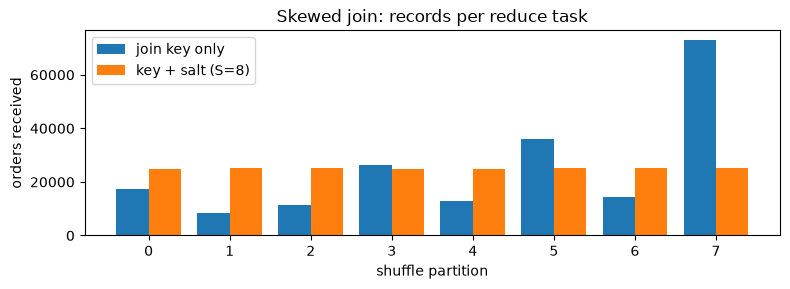

In [11]:
def partition_loads(pairs_list, n):
    loads = np.zeros(n, dtype=int)
    for k, _ in pairs_list:
        loads[part_of(k, n)] += 1
    return loads

S = 8
plain_loads = partition_loads(order_pairs, 8)
rs = random.Random(0)
salted_big = [((k, rs.randrange(S)), a) for k, a in order_pairs]            # big side: random salt
salted_small = [((k, s), seg) for k, seg in cust_pairs for s in range(S)]   # small side: every salt
salted_loads = partition_loads(salted_big, 8)

sc = TinyContext()
salted_join = sc.parallelize(salted_big, 8).join(sc.parallelize(salted_small, 2), n_out=8).collect()
unsalted = [(k, v) for (k, _), v in salted_join]                           # drop the salt
assert key(unsalted) == key(smj)
print(f"max/mean partition load: plain {plain_loads.max() / plain_loads.mean():.2f}, salted {salted_loads.max() / salted_loads.mean():.2f}")
print(f"cost of salting: small side replicated {S}x ({len(salted_small):,} rows instead of {len(cust_pairs):,})")
fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(8)
ax.bar(x - 0.2, plain_loads, 0.4, label="join key only"); ax.bar(x + 0.2, salted_loads, 0.4, label=f"key + salt (S={S})")
ax.set_xlabel("shuffle partition"); ax.set_ylabel("orders received"); ax.set_title("Skewed join: records per reduce task")
ax.legend(); plt.tight_layout(); plt.show()

**What just happened?** With the plain key, one partition gets several times the mean load (the hottest customers), so its task would be the straggler. With salting, the load is nearly even, the join result is identical, and the price is replicating the small side $S$ times. In Spark 3.x/4.x, AQE's **skew join** optimisation (`spark.sql.adaptive.skewJoin.enabled`, on by default) splits oversized partitions automatically for sort-merge joins, so manual salting is now mostly needed for skewed aggregations and for cases AQE cannot detect.

In [12]:
if spark is not None:
    big_df = spark.createDataFrame(orders[["order_id", "customer_id", "amount"]])
    small_df = spark.createDataFrame(customers)
    bhj_df = big_df.join(F.broadcast(small_df), "customer_id")          # force a broadcast hash join
    bhj_df.explain()                                                    # look for BroadcastHashJoin
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")        # disable auto-broadcast ...
    smj_df = big_df.join(small_df, "customer_id")
    smj_df.explain()                                                    # ... to see SortMergeJoin + 2 Exchanges
    spark.conf.set("spark.sql.autoBroadcastJoinThreshold", str(10 * 1024 * 1024))
    assert bhj_df.count() == smj_df.count() == len(ref)
    # Manual salting of a skewed join:
    salted_big_df = big_df.withColumn("salt", (F.rand(seed=0) * S).cast("int"))
    salted_small_df = small_df.crossJoin(spark.range(S).withColumnRenamed("id", "salt"))
    assert salted_big_df.join(salted_small_df, ["customer_id", "salt"]).count() == len(ref)
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


---
## 7. Window functions and UDFs

> 💬 **In plain English:** compute per-row values from neighbouring rows, and prefer built-in functions to your own Python.

A **window function** computes a value for each row from a *window* of related rows (same partition key, ordered), without collapsing rows like `GROUP BY` does: running totals, ranks, previous/next values, moving averages. Spark's `Window.partitionBy(...).orderBy(...)` is the same as SQL's `OVER (PARTITION BY ... ORDER BY ...)`; in a cluster it shuffles by the partition key and sorts within each partition.

In [13]:
win = con.execute('''
    SELECT customer_id, order_id, ts, amount,
           SUM(amount) OVER (PARTITION BY customer_id ORDER BY ts, order_id
                             ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)  AS running_total,
           ROW_NUMBER() OVER (PARTITION BY customer_id ORDER BY ts, order_id)   AS order_number,
           date_diff('minute', LAG(ts) OVER (PARTITION BY customer_id ORDER BY ts, order_id), ts) AS minutes_since_prev,
           RANK() OVER (PARTITION BY day ORDER BY amount DESC)                   AS rank_in_day
    FROM orders
    ORDER BY customer_id, ts, order_id
''').df()
print(win[win.customer_id == 3].head(5).to_string(index=False))

# Check the running total against pandas.
chk = orders.sort_values(["customer_id", "ts", "order_id"])
chk_running = chk.groupby("customer_id")["amount"].cumsum().to_numpy()
assert np.allclose(win["running_total"].to_numpy(), chk_running)
print("running totals match pandas groupby().cumsum()")

 customer_id  order_id                  ts  amount  running_total  order_number  minutes_since_prev  rank_in_day
           3         6 2026-09-01 00:01:29   62.41          62.41             1                <NA>         1175
           3        18 2026-09-01 00:05:20   30.93          93.34             2                   4         3513
           3        20 2026-09-01 00:05:31    8.48         101.82             3                   0         6102
           3        41 2026-09-01 00:09:06   33.89         135.71             4                   4         3194
           3        54 2026-09-01 00:12:42   24.37         160.08             5                   3         4264
running totals match pandas groupby().cumsum()


In [14]:
if spark is not None:
    sdf = spark.createDataFrame(orders)
    w = Window.partitionBy("customer_id").orderBy("ts", "order_id")
    spark_win = (sdf.withColumn("running_total", F.round(F.sum("amount").over(w.rowsBetween(Window.unboundedPreceding, Window.currentRow)), 2))
                    .withColumn("order_number", F.row_number().over(w))
                    .withColumn("prev_ts", F.lag("ts").over(w))
                    .withColumn("rank_in_day", F.rank().over(Window.partitionBy("day").orderBy(F.desc("amount")))))
    spark_win.where("customer_id = 3").orderBy("ts", "order_id").show(5)
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


### 7.1 UDFs vs built-in functions

A **UDF** (user-defined function) lets you run your own Python on each row. In Spark, a plain Python UDF is slow: every row is serialised from the JVM to a Python worker process and back, and the optimiser cannot look inside it. A **pandas UDF** (vectorised UDF) sends whole **Arrow batches** of thousands of rows and runs NumPy/pandas code on them: much faster. A **built-in function** (`F.when`, `F.round`, arithmetic) never leaves the JVM and is optimised by Catalyst: fastest.

We cannot reproduce the JVM ↔ Python hop without Spark, but we can measure the part that matters most: **how many times Python is called**. On 1,000,000 amounts we compare calling a Python function once per row, once per 10,000-row batch with NumPy (the pandas-UDF model), and not at all (a DuckDB built-in SQL expression).

In [15]:
amounts = np.tile(orders["amount"].to_numpy(), 5)                 # 1,000,000 values
big = pd.DataFrame({"amount": amounts})

def tax_row(amount):                                   # "Python UDF": called once per row
    return amount * 1.17 if amount > 50 else amount
def tax_batch(batch):                                  # "pandas UDF": called once per batch, vectorised inside
    return np.where(batch > 50, batch * 1.17, batch)

def run_row():
    return sum(tax_row(a) for a in amounts.tolist())
def run_batches(size=10_000):
    return sum(float(tax_batch(amounts[i:i + size]).sum()) for i in range(0, len(amounts), size))
def run_builtin():
    return con.execute("SELECT SUM(CASE WHEN amount > 50 THEN amount * 1.17 ELSE amount END) FROM big").fetchone()[0]

udf_rows = []
for name, fn, n_calls in [("Python function per row", run_row, len(amounts)),
                          ("vectorised per 10k batch", run_batches, len(amounts) // 10_000),
                          ("built-in SQL expression", run_builtin, 0)]:
    times = []
    for _ in range(2):
        t0 = time.perf_counter(); total = fn(); times.append(time.perf_counter() - t0)
    udf_rows.append({"method": name, "Python calls": n_calls, "seconds (best of 2)": min(times), "result": total})
udf = pd.DataFrame(udf_rows)
assert np.allclose(udf["result"], udf["result"].iloc[0], rtol=1e-9)
udf["slower than fastest"] = (udf["seconds (best of 2)"] / udf["seconds (best of 2)"].min()).round(1)
print(udf.drop(columns="result").round(4).to_string(index=False))
print("same total each way:", round(udf['result'].iloc[0], 2))

                  method  Python calls  seconds (best of 2)  slower than fastest
 Python function per row       1000000               0.2345                 20.8
vectorised per 10k batch           100               0.0113                  1.0
 built-in SQL expression             0               0.0148                  1.3
same total each way: 43714618.39


**What just happened?** All three compute the same total. Calling Python a million times is far slower (see the last column) than calling it 100 times on NumPy batches, and the vectorised batch version is in the same league as the built-in expression (exact numbers depend on machine load). In Spark the gaps are bigger, because a row UDF also pays to move every row between the JVM and a Python worker, and even a pandas UDF pays an Arrow transfer that a built-in never pays; so there the ordering is clearly **row UDF ≪ pandas UDF < built-in**.

> ⚠️ **Common mistake:** writing `@udf` for something Spark already has (`F.when`, `F.regexp_extract`, `F.date_trunc`, `F.transform` on arrays). Search `pyspark.sql.functions` first; if you really need Python, use `@pandas_udf`.

In [16]:
if spark is not None:
    from pyspark.sql.types import DoubleType
    sdf = spark.createDataFrame(orders[["order_id", "amount"]])
    @F.udf(DoubleType())                                 # F.udf, so the name `udf` (results table above) is not overwritten
    def tax_udf(a):                                      # row-at-a-time Python UDF
        return a * 1.17 if a > 50 else a
    @F.pandas_udf(DoubleType())
    def tax_pandas_udf(a: pd.Series) -> pd.Series:       # vectorised over Arrow batches
        return a.where(a <= 50, a * 1.17)
    builtin = F.when(F.col("amount") > 50, F.col("amount") * 1.17).otherwise(F.col("amount"))
    for name, col in [("python udf", tax_udf("amount")), ("pandas udf", tax_pandas_udf("amount")), ("built-in", builtin)]:
        t0 = time.perf_counter(); s = sdf.select(F.sum(col)).first()[0]
        print(f"{name:10s} {time.perf_counter() - t0:6.2f}s  total={s:,.2f}")
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


---
## 8. Partitioned Parquet and the small-files problem

> 💬 **In plain English:** many tiny files are slow; write fewer, bigger files.

Spark writes one file **per task per output partition value**. If 200 tasks each contain rows for all 30 days and you write with `partitionBy("day")`, you get up to $200 \times 30 = 6{,}000$ files, each tiny. Every file costs a metadata lookup, an open call and a footer read (and on cloud storage, an HTTP request). Too many small files make reads slow and can overload the storage metadata service: this is the **small-files problem**.

The fix is to arrange the data so each output partition is written by few tasks: `df.repartition("day").write.partitionBy("day")` (one shuffle, then one file per day), `coalesce(n)` before writing, the `maxRecordsPerFile` option, or periodic **compaction** (Delta Lake `OPTIMIZE`, Iceberg `rewrite_data_files`).

We reproduce both layouts with PyArrow (which writes the same Hive-style folders as Spark).

In [17]:
tbl = pa.Table.from_pandas(orders.drop(columns=["ts"]), preserve_index=False)

def write_like_spark(table, root, n_tasks):
    # Simulate n_tasks Spark tasks, each writing its own slice with partitionBy("day").
    rows = table.num_rows
    table = table.take(np.random.default_rng(0).permutation(rows))   # input splits hold rows of every day
    for t in range(n_tasks):
        part = table.slice(t * rows // n_tasks, (t + 1) * rows // n_tasks - t * rows // n_tasks)
        ds.write_dataset(part, root, format="parquet", partitioning=["day"], partitioning_flavor="hive",
                         basename_template=f"part-{t:05d}-{{i}}.parquet", existing_data_behavior="overwrite_or_ignore")

layouts = {}
small_root, compact_root = WORK / "orders_small_files", WORK / "orders_compacted"
write_like_spark(tbl, small_root, n_tasks=40)                     # 40 tasks x 30 days
write_like_spark(tbl, compact_root, n_tasks=1)                    # like repartition("day"): 1 file per day

def read_all(root):
    return ds.dataset(root, format="parquet", partitioning="hive").to_table(columns=["country", "amount"])

rows_out = []
for name, root in [("40 tasks, no repartition", small_root), ("repartition by day / compacted", compact_root)]:
    files = list(root.rglob("*.parquet"))
    times = []
    for _ in range(3):                                            # best of 3 reads
        t0 = time.perf_counter(); n_rows = read_all(root).num_rows; times.append(time.perf_counter() - t0)
    best = min(times)
    rows_out.append({"layout": name, "files": len(files),
                     "avg file KB": round(np.mean([f.stat().st_size for f in files]) / 1e3, 1),
                     "total MB": round(sum(f.stat().st_size for f in files) / 1e6, 2),
                     "read seconds (best of 3)": round(best, 3),
                     "rows": n_rows})
small_files = pd.DataFrame(rows_out)
print(small_files.to_string(index=False))

                        layout  files  avg file KB  total MB  read seconds (best of 3)   rows
      40 tasks, no repartition   1200          6.1      7.29                     0.856 200000
repartition by day / compacted     30        100.7      3.02                     0.078 200000


**What just happened?** The same 200,000 rows were written twice. With 40 writer tasks and no repartitioning we get 40 × 30 = 1,200 files of only a few KB; after "repartitioning by day" we get 30 files. The many-small-files layout is **larger on disk** (every file repeats a header, footer and schema, and small files compress worse) and **slower to read** even on a local SSD; on S3 or ADLS, where each file is a network request, the gap is far bigger. Typical guidance is files of about 128 MB–1 GB.

In [18]:
if spark is not None:
    sdf = spark.createDataFrame(orders.drop(columns=["ts"]))
    out = str(WORK / "spark_orders")
    (sdf.repartition("day")                       # one shuffle so each day is in one task
        .write.mode("overwrite")
        .partitionBy("day")                       # Hive-style folders day=2026-09-01/ ...
        .option("maxRecordsPerFile", 1_000_000)   # cap file size for very big days
        .parquet(out))
    back = spark.read.parquet(out).where(F.col("day") == "2026-09-20")   # partition pruning on read
    back.explain()                                # look for PartitionFilters: [isnotnull(day), (day = 2026-09-20)]
    print("files written:", len(list(Path(out).rglob("*.parquet"))), "| rows on 2026-09-20:", back.count())
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


---
## 9. MLlib: a pipeline with cross-validation

> 💬 **In plain English:** Spark has its own scikit-learn-like toolkit for training models on huge tables.

**MLlib** (`pyspark.ml`) trains models on DataFrames distributed across the cluster. Its design inspired, and closely mirrors, scikit-learn's: **Transformers** (`transform`), **Estimators** (`fit` → a model, which is a Transformer), and a **Pipeline** that chains them. One difference: Spark models expect all features in **one vector column**, built by `VectorAssembler`.

We predict whether a customer will make a large next order from simple features, with Spark (if available) and with the scikit-learn equivalent.

In [19]:
# A small churn-style dataset: features per customer from their orders.
feat = (orders.groupby("customer_id")
              .agg(n_orders=("order_id", "count"), avg_amount=("amount", "mean"), max_amount=("amount", "max"),
                   n_categories=("category", "nunique"))
              .reset_index().merge(customers, on="customer_id"))
logit = -3.0 + 0.04 * feat.avg_amount + 0.8 * (feat.segment == "vip") + 0.3 * np.log1p(feat.n_orders)
feat["label"] = (RNG.random(len(feat)) < 1 / (1 + np.exp(-logit))).astype(int)
num_cols, cat_cols = ["n_orders", "avg_amount", "max_amount", "n_categories"], ["segment"]
print(feat.head(3).to_string(index=False), f"\n{len(feat)} customers, positive rate {feat.label.mean():.2f}")

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import roc_auc_score

train, test = train_test_split(feat, test_size=0.25, random_state=0, stratify=feat.label)
pipe = Pipeline([
    ("assemble", ColumnTransformer([("num", StandardScaler(), num_cols),             # ~ VectorAssembler + StandardScaler
                                    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])),  # ~ StringIndexer + OneHotEncoder
    ("lr", LogisticRegression(max_iter=1000)),
])
grid = GridSearchCV(pipe, {"lr__C": [0.01, 0.1, 1.0, 10.0]}, cv=3, scoring="roc_auc")  # ~ CrossValidator + ParamGridBuilder
grid.fit(train[num_cols + cat_cols], train.label)
auc = roc_auc_score(test.label, grid.predict_proba(test[num_cols + cat_cols])[:, 1])
print(f"scikit-learn: best C = {grid.best_params_['lr__C']}, CV AUC = {grid.best_score_:.3f}, test AUC = {auc:.3f}")

 customer_id  n_orders  avg_amount  max_amount  n_categories segment  label
           0         1   55.240000       55.24             1     new      0
           1     64353   39.904407      263.14             4     new      1
           2     24219   39.937635      296.32             4     new      1 
4414 customers, positive rate 0.33


scikit-learn: best C = 0.1, CV AUC = 0.707, test AUC = 0.703


In [20]:
if spark is not None:
    from pyspark.ml import Pipeline as SparkPipeline
    from pyspark.ml.feature import VectorAssembler, StandardScaler as SparkScaler, StringIndexer, OneHotEncoder as SparkOHE
    from pyspark.ml.classification import LogisticRegression as SparkLR
    from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
    from pyspark.ml.evaluation import BinaryClassificationEvaluator

    s_train, s_test = spark.createDataFrame(train), spark.createDataFrame(test)
    stages = [
        StringIndexer(inputCol="segment", outputCol="segment_idx"),
        SparkOHE(inputCols=["segment_idx"], outputCols=["segment_ohe"]),
        VectorAssembler(inputCols=num_cols, outputCol="num_vec"),
        SparkScaler(inputCol="num_vec", outputCol="num_scaled", withMean=True, withStd=True),
        VectorAssembler(inputCols=["num_scaled", "segment_ohe"], outputCol="features"),
        SparkLR(featuresCol="features", labelCol="label", maxIter=100),
    ]
    lr = stages[-1]
    cv = CrossValidator(estimator=SparkPipeline(stages=stages),
                        estimatorParamMaps=ParamGridBuilder().addGrid(lr.regParam, [0.0, 0.01, 0.1]).build(),
                        evaluator=BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC"),
                        numFolds=3, seed=0, parallelism=2)
    cv_model = cv.fit(s_train)
    test_auc = BinaryClassificationEvaluator(labelCol="label").evaluate(cv_model.transform(s_test))
    print("Spark MLlib: CV AUCs", [round(float(m), 3) for m in cv_model.avgMetrics], "test AUC", round(test_auc, 3))
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


**What just happened?** scikit-learn's `ColumnTransformer` + `LogisticRegression` + `GridSearchCV` is the single-machine twin of Spark's `VectorAssembler`/`StandardScaler`/`OneHotEncoder` + `LogisticRegression` + `CrossValidator`. The data is synthetic with a known signal, so a test AUC clearly above 0.5 (printed above) is expected.

| scikit-learn | Spark MLlib (`pyspark.ml`) |
|---|---|
| `Pipeline([...])` | `Pipeline(stages=[...])` |
| `ColumnTransformer` / `np.column_stack` | `VectorAssembler` (all features → one vector column) |
| `OneHotEncoder` on strings | `StringIndexer` then `OneHotEncoder` |
| `LogisticRegression(C=...)` | `LogisticRegression(regParam=λ, elasticNetParam=α)`; for L2, roughly $C = 1/(n\lambda)$ |
| `GridSearchCV(cv=3)` | `CrossValidator(numFolds=3)` + `ParamGridBuilder` |
| `roc_auc_score` | `BinaryClassificationEvaluator(metricName="areaUnderROC")` |

Use MLlib when the **training data itself** is too big for one machine and the model is a classic one (linear models, trees, ALS for recommendations, k-means). For deep learning, Spark is typically used for the data preparation, and training runs in PyTorch (for example with `TorchDistributor` or Ray), see [distributed training](../../05_Deep_Learning/11_distributed_training.ipynb).

---
## 10. Structured Streaming: rate source and watermarks

> 💬 **In plain English:** run the same query over and over on newly arriving data, and decide how long to wait for latecomers.

**Structured Streaming** treats a stream as an **unbounded table** that keeps growing; you write the same DataFrame query as for batch, and Spark runs it **incrementally** in **micro-batches** (by default, a new micro-batch starts as soon as the previous one finishes; a `trigger` can set an interval). For aggregations over **event-time windows**, it keeps per-window state. A **watermark** (`withWatermark("timestamp", "10 seconds")`) tells Spark how late data may arrive: at each micro-batch, watermark = (max event time seen so far) − 10 s. Windows that end before the watermark are **final**: their state is dropped and later rows for them are ignored.

The **rate source** generates `(timestamp, value)` rows at a fixed rate and exists for testing. The Spark cell runs it for about 8 seconds; the fallback simulates the same micro-batch engine in pure Python, with a few deliberately late rows. The full theory (tumbling, sliding and session windows, exactly-once, checkpoints) is in [04 · Stream processing from scratch](04_stream_processing_from_scratch.ipynb).

In [21]:
if spark is not None:
    stream = spark.readStream.format("rate").option("rowsPerSecond", 20).load()     # columns: timestamp, value
    windowed = (stream.withWatermark("timestamp", "10 seconds")
                      .groupBy(F.window("timestamp", "5 seconds"))
                      .agg(F.count("*").alias("rows"), F.sum("value").alias("total")))
    batches = []
    def keep(batch_df, batch_id):                       # foreachBatch: plain DataFrame per micro-batch
        batches.append((batch_id, batch_df.toPandas()))
    query = (windowed.writeStream.outputMode("update").foreachBatch(keep)
                     .trigger(processingTime="1 second").start())
    try:
        time.sleep(8)
    finally:
        query.stop()
    for bid, pdf in batches[:6]:
        print("micro-batch", bid, "updated windows:", len(pdf), pdf["rows"].tolist())
else:
    print(SKIP)

⏭️ PySpark/Java not available: Spark cell skipped. The fallback below shows the same idea.


In [22]:
def simulate_microbatches(rate=20, seconds=30, window=5, delay=10, late_every=15, late_by=13, trigger=1.0):
    # Pure-Python model of Structured Streaming: event-time windows, update mode, watermark.
    rows = []                                                   # (arrival_time, event_time, value)
    for v in range(rate * seconds):
        event_t = v / rate
        arrival = event_t + (late_by if v % late_every == 0 and v > 0 else 0.05)   # a few rows arrive very late
        rows.append((arrival, event_t, v))
    rows.sort()
    state, max_event, watermark = {}, 0.0, -1e9
    log, b, i = [], 0, 0
    while i < len(rows):
        end = (b + 1) * trigger                                  # rows that arrived during this trigger interval
        batch = []
        while i < len(rows) and rows[i][0] < end:
            batch.append(rows[i]); i += 1
        updated, dropped, late_ok = set(), 0, 0
        for arrival, et, v in batch:
            w_start = et - et % window
            if w_start + window <= watermark:                    # window already final: too late
                dropped += 1
                continue
            late_ok += arrival - et > 1                          # a late row that still made it
            cnt, tot = state.get(w_start, (0, 0))
            state[w_start] = (cnt + 1, tot + v)
            updated.add(w_start)
            max_event = max(max_event, et)
        watermark = max_event - delay                            # used from the NEXT batch on, like Spark
        for w in [w for w in state if w + window <= watermark]:  # finalised windows: drop their state
            del state[w]
        log.append({"batch": b, "rows in": len(batch), "updated windows": sorted(updated),
                    "late rows accepted": late_ok, "late rows dropped": dropped, "watermark (s)": round(max(watermark, 0), 2), "windows in state": len(state)})
        b += 1
    return pd.DataFrame(log)

mb = simulate_microbatches()
print(mb.iloc[8:24].to_string(index=False))                      # the interesting middle part
print(f"{len(mb)} micro-batches | late rows accepted: {mb['late rows accepted'].sum()} | "
      f"late rows dropped: {mb['late rows dropped'].sum()} | max windows in state: {mb['windows in state'].max()}")

 batch  rows in   updated windows  late rows accepted  late rows dropped  watermark (s)  windows in state
     8       19             [5.0]                   0                  0            0.0                 2
     9       18             [5.0]                   0                  0            0.0                 2
    10       19       [5.0, 10.0]                   0                  0            0.9                 3
    11       19            [10.0]                   0                  0            1.9                 3
    12       18            [10.0]                   0                  0            2.9                 3
    13       20       [0.0, 10.0]                   1                  0            3.9                 3
    14       20       [0.0, 10.0]                   1                  0            4.9                 3
    15       19 [0.0, 10.0, 15.0]                   1                  0            5.9                 3
    16       21            [15.0]             

**What just happened?** Each micro-batch ingests the rows that arrived during one second and emits only the windows it **updated** (update output mode). Once the maximum event time passes 15 s, the watermark (max event time − 10 s) passes the end of window [0, 5) and that window's state is dropped; the number of windows kept in state stays small instead of growing forever. Rows that arrive 13 s late are still accepted while their window is open, but once the watermark has passed their window they are counted as **dropped**. That is the trade-off a watermark encodes: **a longer delay = more complete results, but more state and later final answers.**

> 🎓 **Exam / interview tip:** Structured Streaming output modes: **append** (emit a window once, when it is final; requires a watermark for aggregations), **update** (emit changed rows each micro-batch), **complete** (emit the whole result table each time; only for aggregations). Exactly-once end-to-end needs a replayable source (Kafka), checkpointed state and offsets, and an idempotent or transactional sink.

---
## 11. Spark in the cloud: Databricks, EMR and friends

> 💬 **In plain English:** in companies the same Spark code runs on rented clusters managed by a cloud provider.

The code above is the same code that runs on a managed cluster; what changes is who provisions the machines and the storage underneath.

| platform | what it is | notes |
|---|---|---|
| **Databricks** (AWS, Azure, GCP) | managed Spark from Spark's creators, notebooks, jobs, serverless compute | **Delta Lake** tables (ACID on Parquet), the **Photon** vectorised engine, Unity Catalog for governance |
| **AWS EMR** | managed Hadoop/Spark on EC2, EKS or EMR Serverless | reads S3; you choose instance types and autoscaling |
| **Google Dataproc** | managed Spark/Hadoop on GCP, also serverless | reads GCS, integrates with BigQuery |
| **Azure Synapse / Microsoft Fabric** | Spark pools inside Microsoft's analytics platforms | OneLake, Delta tables |
| **Kubernetes** | Spark's native K8s scheduler | self-managed; also via the Spark operator |
| **Spark Connect** (Spark 3.4+) | thin client protocol: your Python talks to a remote Spark driver | in Spark 4.x the lightweight `pyspark-client` package needs no local JVM |

Mapping of concepts:

| this notebook | in production |
|---|---|
| `local[2]` | a cluster with N executors × C cores each |
| temp folder with Parquet | a data lake (S3, ADLS, GCS) with Delta Lake, Apache Iceberg or Hudi tables |
| `spark.sql.shuffle.partitions = 8` | AQE picks the number of shuffle partitions at run time |
| `rate` source | Kafka, Kinesis, Event Hubs, Pub/Sub |
| manual compaction | `OPTIMIZE` (Delta), `rewrite_data_files` (Iceberg), auto-compaction |

---
## 12. 🔗 How this connects to modern AI

> 💬 **In plain English:** Spark prepares and scores the data behind many AI systems.

- **Training data preparation.** Spark (and Ray) jobs filter, deduplicate, tokenise and shard web-scale corpora for LLM pre-training and fine-tuning; skewed domains and huge documents are the classic stragglers. See [fine-tuning](../../08_LLM/03_fine_tuning/01_fine_tuning.ipynb) and [synthetic data](../../08_LLM/10_synthetic_data/01_synthetic_data.ipynb).
- **Batch inference and embeddings.** Scoring millions of rows or embedding a document collection for RAG is a `mapPartitions` job where each task loads the model once and processes a whole partition (the same pattern as a pandas UDF). See [RAG](../../08_LLM/02_rag/01_rag_fundamentals.ipynb) and the [RAG pipeline](../../08_LLM/19_industry_rag_pipeline.ipynb).
- **Feature engineering and feature stores.** Window functions over event tables (running totals, counts in the last 7 days, time since previous event) are exactly how batch features are computed before they are loaded into a feature store: [feature stores](../../15_MLOps/12_feature_stores.ipynb), [SQL for ML features](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb).
- **Classic ML at scale.** MLlib's ALS powers large recommenders, and its pipelines mirror scikit-learn ([recommendation systems](../../03_Machine_Learning/09_recommendation_systems)). Pipeline orchestration of Spark jobs: [orchestration](../../15_MLOps/03_pipeline_orchestration/01_orchestration.ipynb).
- **Streaming features.** Structured Streaming with watermarks computes near-real-time features for fraud and ads models ([streaming model updates](../../03_Machine_Learning/12_online_learning/02_industry_streaming_model_updates.ipynb)).

---
## 13. Recap

- Spark = a **driver** that plans and **executors** that run **tasks**, one per **partition** per **stage**; `local[*]` runs the same model on one machine.
- **Transformations are lazy**; **actions** trigger jobs. The **lineage (DAG)** is used both for planning and for recomputing lost partitions.
- **Narrow** dependencies pipeline inside a stage; **wide** dependencies need a **shuffle** and start a new stage. Count `Exchange` operators in `explain()`.
- Prefer `reduceByKey` / DataFrame aggregations (map-side partial aggregation) over `groupByKey`.
- **Cache** only what several actions reuse and is costly to recompute.
- **Broadcast hash join** when one side is small (default threshold 10 MB): no shuffle of the big side. **Sort-merge join** for two big tables: shuffle both, sort, merge. Fix skew with **AQE** or **salting**.
- **Window functions** compute per-row values over partitions; prefer **built-ins** over Python UDFs, and **pandas UDFs** over row UDFs when Python is unavoidable.
- Write **partitioned Parquet** with few, large files (`repartition` before `partitionBy`, compaction) to avoid the **small-files problem**.
- **MLlib** pipelines mirror scikit-learn; **Structured Streaming** runs batch-style queries incrementally, with **watermarks** bounding state and lateness.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** Classify as narrow or wide: `map`, `filter`, `union`, `distinct`, `repartition(10)`, `coalesce(2)`, `reduceByKey`, a `join` of two RDDs that were already partitioned with the same partitioner.

<details><summary>Show solution</summary>

Narrow: `map`, `filter`, `union` (output partitions are just the parents' partitions), `coalesce(2)` (merges neighbouring partitions without a shuffle), and the **co-partitioned join** (matching keys are already in partitions with the same index, so each output partition reads one partition from each parent). Wide: `distinct` (needs all copies of a value together), `repartition(10)` (full shuffle), `reduceByKey` (shuffle, with map-side combine).

</details>

**2. (Easy, conceptual)** How many **jobs** and **stages** does this code run, and why?
```python
words = sc.textFile("logs").flatMap(lambda l: l.split()).map(lambda w: (w, 1))
counts = words.reduceByKey(add)
counts.count()
counts.collect()
```

<details><summary>Show solution</summary>

Two actions → **two jobs**. Each job's DAG has **two stages** (read → flatMap → map, then the post-shuffle reduce), split at the `reduceByKey` shuffle. In the second job Spark finds the shuffle files of the first stage still on the executors and marks that stage as **skipped**, so only one stage actually runs. (Our `TinyRDD` keeps shuffle output for the same reason.)

</details>

**3. (Medium, coding)** Using `TinyContext`, compute the **average order amount per country** with `reduceByKey` (no `groupByKey`), and check it against pandas.

<details><summary>Show solution</summary>

```python
sc = TinyContext()
rdd = sc.parallelize(list(zip(orders.country, orders.amount)), 8)
sums = rdd.mapValues(lambda a: (a, 1)).reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]))
avg = {k: s / c for k, (s, c) in sums.collect()}
expected = orders.groupby("country")["amount"].mean()
assert all(np.isclose(avg[k], v) for k, v in expected.items())
```

The value is the algebraic state `(sum, count)`; averaging averages would be wrong (notebook 02, Section 2.3).

</details>

**4. (Medium, conceptual)** You join a 2 TB `events` table with a 40 MB `countries` table and a 900 GB `users` table. Which join strategy would Spark pick for each join with default settings, and what could you change?

<details><summary>Show solution</summary>

`events ⋈ countries`: 40 MB is above the default `autoBroadcastJoinThreshold` (10 MB), so the static plan is a sort-merge join, unless AQE sees the runtime size and converts it (AQE also has its own threshold, `spark.sql.adaptive.autoBroadcastJoinThreshold`). Since 40 MB easily fits in executor memory, force it with `F.broadcast(countries)` or raise the threshold: then the 2 TB side is never shuffled. `events ⋈ users`: both are large, so **sort-merge join**, shuffling both sides. Improvements: filter and project before the join, pre-bucket both tables by `user_id` (bucketed tables avoid the shuffle), and handle hot users with AQE skew join or salting.

</details>

**5. (Medium, coding)** With DuckDB, compute for each customer the **moving average of the current and two previous order amounts** (ordered by `ts, order_id`) and check it against pandas `rolling`.

<details><summary>Show solution</summary>

```python
mov = con.execute('''
    SELECT customer_id, order_id,
           AVG(amount) OVER (PARTITION BY customer_id ORDER BY ts, order_id
                             ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS mov3
    FROM orders ORDER BY customer_id, ts, order_id
''').df()
chk = orders.sort_values(["customer_id", "ts", "order_id"])
expected = chk.groupby("customer_id")["amount"].transform(lambda s: s.rolling(3, min_periods=1).mean())
assert np.allclose(mov["mov3"].to_numpy(), expected.to_numpy())
```

In Spark: `F.avg("amount").over(Window.partitionBy("customer_id").orderBy("ts", "order_id").rowsBetween(-2, 0))`.

</details>

**6. (Medium, conceptual)** A daily job writes a year of data with `df.write.partitionBy("day").parquet(path)` from 200 tasks. How many files can it create, and give three ways to fix it.

<details><summary>Show solution</summary>

Up to $365 \times 200 = 73{,}000$ files (each task writes one file per day it contains). Fixes: (1) `df.repartition("day")` before writing, so each day is in one task (then use `maxRecordsPerFile` to split very big days); (2) `coalesce(n)` to fewer tasks when the data is small; (3) periodic compaction, such as Delta Lake `OPTIMIZE` / auto-compaction or Iceberg `rewrite_data_files`; also (4) choose a coarser partition column (month) if days are tiny.

</details>

**7. (Hard, coding)** Implement a **two-stage salted aggregation** with `TinyContext`: count orders per `customer_id` by first reducing on `(customer_id, salt)` with $S = 8$ random salts, then on `customer_id`. Check the result against `value_counts`, and show that the largest stage-1 reduce partition is smaller than without salting.

<details><summary>Show solution</summary>

```python
rs = random.Random(1)
S = 8
sc = TinyContext()
base = sc.parallelize([(int(c), 1) for c in orders.customer_id], 8)
stage1 = base.map(lambda kv: ((kv[0], rs.randrange(S)), kv[1])).reduceByKey(lambda a, b: a + b, n_out=8)
stage2 = stage1.map(lambda kv: (kv[0][0], kv[1])).reduceByKey(lambda a, b: a + b, n_out=8)
counts = dict(stage2.collect())
assert counts == orders.customer_id.value_counts().to_dict()

# Load of the reduce side, measured *before* the map-side combine (what groupByKey would receive):
plain = np.bincount([part_of(int(c), 8) for c in orders.customer_id], minlength=8)
salted = np.bincount([part_of((int(c), rs.randrange(S)), 8) for c in orders.customer_id], minlength=8)
assert salted.max() < plain.max()
```

Note that the random salt is drawn when `stage1` is computed; because shuffle output is kept, `stage2` reuses it consistently. In Spark the same holds within one job, but a recomputation after a failure would draw new salts, which is still correct for counting (any assignment of salts gives the same totals).

</details>

## Further reading (additional learning resources)

- Zaharia et al., "Resilient Distributed Datasets: A Fault-Tolerant Abstraction for In-Memory Cluster Computing", NSDI 2012.
- Armbrust et al., "Spark SQL: Relational Data Processing in Spark", SIGMOD 2015; Armbrust et al., "Structured Streaming", SIGMOD 2018.
- Chambers & Zaharia, *Spark: The Definitive Guide* (O'Reilly); Damji et al., *Learning Spark* (2nd ed., O'Reilly, free from Databricks).
- Kleppmann, *Designing Data-Intensive Applications*, ch. 10 (batch processing, joins, skew).
- Apache Spark documentation: SQL performance tuning (AQE, join strategies) https://spark.apache.org/docs/latest/sql-performance-tuning.html and the Structured Streaming programming guide.
- GeeksforGeeks: [Introduction to PySpark](https://www.geeksforgeeks.org/introduction-pyspark-distributed-computing-with-apache-spark/), [Difference between RDD, DataFrame and Dataset](https://www.geeksforgeeks.org/difference-between-rdd-dataframe-and-dataset-in-spark/).

## Next notebook
➡️ [04 · Stream processing from scratch](04_stream_processing_from_scratch.ipynb): event time vs processing time, tumbling/sliding/session windows, watermarks, exactly-once sinks, checkpoints and backpressure.

In [23]:
# Clean up: stop Spark (if it was started) and delete the temporary folder.
if spark is not None:
    spark.stop()
con.close()
shutil.rmtree(WORK, ignore_errors=True)
print("temporary folder removed:", not WORK.exists())

temporary folder removed: True
